In [1]:
import os
import numpy as np
import pandas as pd
import umap
import seaborn as sns 
import matplotlib.pyplot as plt

c:\Users\jvill\miniconda3\envs\hsi_machine_learning\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### snRNA-seq data

In [2]:
sn_3712_path = r"C:\Users\jvill\OneDrive - UC San Diego\integrated_pipeline\snRNA\umap_coordinates_3712.csv"
sn_3723_path = r"C:\Users\jvill\OneDrive - UC San Diego\integrated_pipeline\snRNA\umap_coordinates_3723.csv" 

sn_3712_df = pd.read_csv(sn_3712_path)
sn_3723_df = pd.read_csv(sn_3723_path)

In [3]:
sn_3712_df['sample'] = '3712'
sn_3723_df['sample'] = '3723'

In [4]:
sn_3712_df.head(5)

,Unnamed: 0,umap_1,umap_2,v2.subclass.l1,sample
0,PA10_AAACCCAAGAAGCGAA-1,6.535445,-1.055000,PC,3712
1,PA10_AAACCCAAGAGCCGTA-1,2.135303,11.388339,TAL,3712
2,PA10_AAACCCAAGATGCAGC-1,-0.244590,-0.772024,DTL,3712
3,PA10_AAACCCACAATAGTGA-1,2.480744,11.574912,TAL,3712
4,PA10_AAACCCACAATCGCCG-1,-1.947224,-13.664860,FIB,3712


In [5]:
sn_3723_df.head(5)

,Unnamed: 0,umap_1,umap_2,v2.subclass.l1,sample
0,KC125_AAACCCACAACACAAA-1,7.130124,1.667768,CNT,3723
1,KC125_AAACCCACAGTCGCAC-1,6.593482,0.286573,PC,3723
2,KC125_AAACCCAGTGCAACAG-1,7.362960,-0.313086,CNT,3723
3,KC125_AAACCCATCATATGGC-1,7.032190,2.476495,CNT,3723
4,KC125_AAACCCATCCAGGACC-1,-4.995205,0.547091,PT,3723


In [6]:
plot_df = pd.concat([sn_3712_df, sn_3723_df], axis=0)  

In [7]:
plot_df['v2.subclass.l1'] = plot_df['v2.subclass.l1'].replace({"DTL":"TDL"})

In [ ]:
import matplotlib.patheffects as pe
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

# 1. Filter out low-count categories
plot_df = plot_df[
    plot_df["v2.subclass.l1"].isin(
        plot_df["v2.subclass.l1"]
        .value_counts()[plot_df["v2.subclass.l1"].value_counts() > 3]
        .index
    )
]

# 2. Shuffle the plotting order to prevent occlusion/stacking of clusters
plot_df = plot_df.sample(frac=1, random_state=42)

# 3. Curated, publication-quality categorical palette for kidney cell types
hue_colors = {
    "PT": "#2ca02c",  # Proximal Tubule (Green)
    "TDL": "#ffbb78",  # Thin Descending Limb (Light Orange)
    "ATL": "#aec7e8",  # Ascending Thin Limb (Light Blue)
    "TAL": "#ff7f0e",  # Thick Ascending Limb (Orange)
    "DCT": "#9467bd",  # Distal Convoluted Tubule (Purple)
    "CNT": "#c5b0d5",  # Connecting Tubule (Light Purple)
    "PC": "#1f77b4",  # Principal Cell (Steel Blue)
    "IC": "#17becf",  # Intercalated Cell (Teal/Cyan)
    "PapE": "#9edae5",  # Papillary Epithelium (Light Cyan)
    "POD": "#d62728",  # Podocyte (Crimson Red)
    "PEC": "#ff9896",  # Parietal Epithelial Cell (Light Red)
    "EC": "#bcbd22",  # Endothelial Cell (Olive Green)
    "VSM/P": "#dbdb8d",  # Vascular Smooth Muscle/Pericyte (Light Olive)
    "FIB": "#8c564b",  # Fibroblast (Brown)
    "NEU": "#7f7f7f",  # Neuron (Grey)
    "Myeloid": "#e377c2",  # Myeloid (Pink)
    "Lymphoid": "#f7b6d2",  # Lymphoid (Light Pink)
}

fig, ax = plt.subplots(figsize=(4, 8))

# 4. Plot with alpha transparency, no edge borders, and rasterized points
sns.scatterplot(
    data=plot_df,
    x="umap_1",
    y="umap_2",
    hue="v2.subclass.l1",
    s=1,
    alpha=0.75,
    edgecolor="none",
    palette=hue_colors,
    rasterized=True,  # Keeps vector text clean while rasterizing dense points
    ax=ax,
)

# Extract coordinates and labels for centroid text placement
embeddings = plot_df[["umap_1", "umap_2"]].values
labels = plot_df["v2.subclass.l1"].values
unique_labels = plot_df["v2.subclass.l1"].unique()

# # 5. Place clean, bold labels at each cluster's median centroid
# for label in unique_labels:
#     if label not in hue_colors:
#         continue
#     mask = labels == label
#     # Using median for both coordinates yields a better geometric center
#     centroid_x = np.median(embeddings[mask, 0])
#     centroid_y = np.median(embeddings[mask, 1])

#     ax.text(
#         centroid_x,
#         centroid_y,
#         label,
#         fontsize=12,  # Adjusted to fit 6x6 figure nicely
#         fontweight="bold",
#         ha="center",
#         va="center",
#         color="black",
#         path_effects=[pe.withStroke(linewidth=3, foreground="white")],
#         zorder=100,
#     )

# Formatting axes
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_xticklabels([])
ax.set_yticklabels([])
sns.despine(ax=ax, top=True, right=True, left=True, bottom=True)
ax.tick_params(left=False, bottom=False)

# Remove the default legend (since we have text labels on centroids)
legend = ax.get_legend()
if legend is not None:
    legend.remove()

plt.savefig(
    r"C:\Users\jvill\OneDrive - UC San Diego\integrated_pipeline\snRNA\umap_plot.png",
    bbox_inches="tight",
    dpi=300,
    transparent=True
)
plt.show()


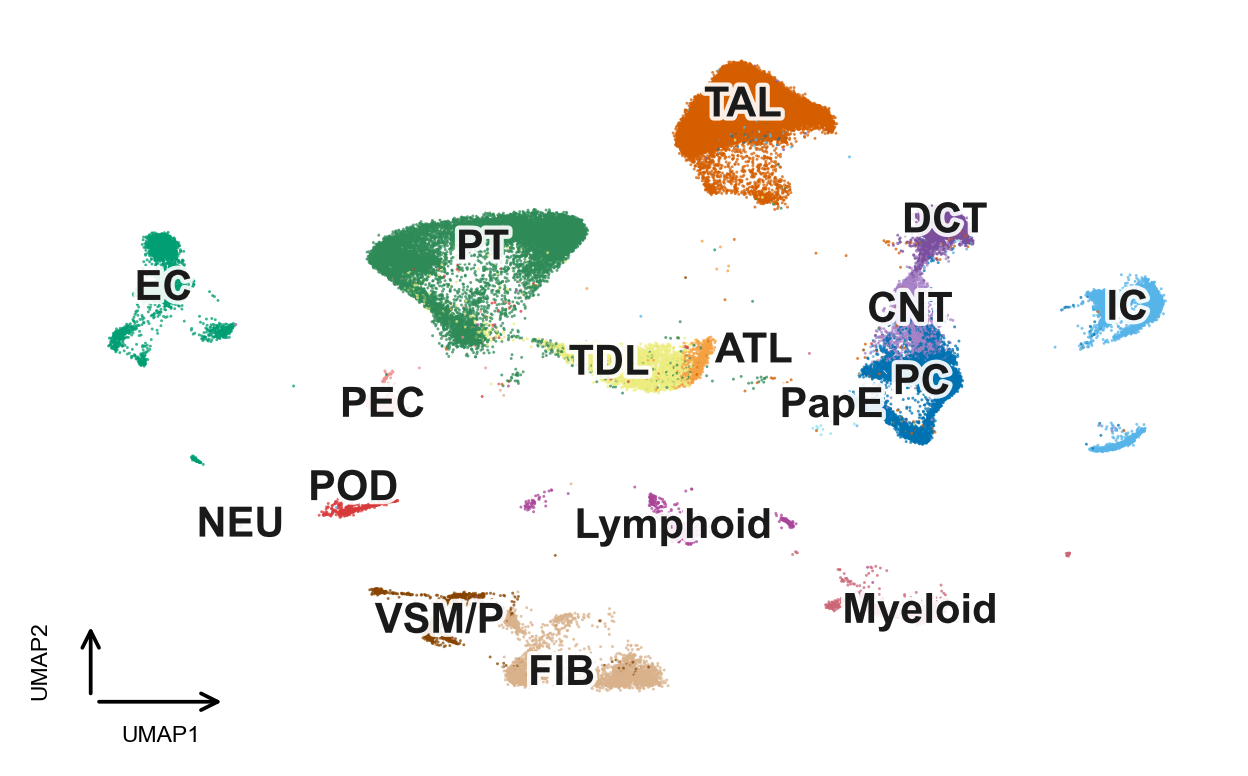

In [69]:
import matplotlib.patheffects as pe
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

# -------------------------------------------------------------------------
# 1. Filter out low-count categories & shuffle
# -------------------------------------------------------------------------
counts = plot_df["v2.subclass.l1"].value_counts()
plot_df = plot_df[plot_df["v2.subclass.l1"].isin(counts[counts > 3].index)].copy()
plot_df = plot_df.sample(frac=1, random_state=42)

# -------------------------------------------------------------------------
# 2. Lineage-Grouped Kidney Color Palette
# -------------------------------------------------------------------------
# Grouped by functional/anatomical compartment for intuitive visual hierarchy
hue_colors = {
    # Glomerular / Podocytes (Warm Reds / Corals)
    "POD": "#D9383A",      # Podocyte
    "PEC": "#F28E8E",      # Parietal Epithelial Cell
    
    # Proximal Tubule (Emerald Green)
    "PT": "#2E8B57",       # Proximal Tubule
    
    # Loop of Henle (Ambers / Warm Oranges)
    "TDL": "#eded80",      # Thin Descending Limb
    "ATL": "#f5a142",      # Ascending Thin Limb
    "TAL": "#D55E00",      # Thick Ascending Limb
    
    # Distal Nephron (Purples / Indigos)
    "DCT": "#7B4F9D",      # Distal Convoluted Tubule
    "CNT": "#A883C7",      # Connecting Tubule
    
    # Collecting Duct (Blues / Cyan)
    "PC": "#0072B2",       # Principal Cell
    "IC": "#56B4E9",       # Intercalated Cell
    "PapE": "#8EE5EE",     # Papillary Epithelium
    
    # Endothelial (Teal / Sea Green)
    "EC": "#009E73",       # Endothelial Cell
    
    # Stromal / Interstitial (Warm Tans / Browns / Slate)
    "VSM/P": "#874400",    # Vascular Smooth Muscle / Pericyte
    "FIB": "#d9b28b",      # Fibroblast
    "NEU": "#7F7F7F",      # Neuronal
    
    # Immune (Berry / Magentas)
    "Myeloid": "#CC6677",  # Myeloid
    "Lymphoid": "#AA4499", # Lymphoid
}

# -------------------------------------------------------------------------
# 3. Figure Setup (Standard Single-Column Width: ~3.3 inches / ~85 mm)
# -------------------------------------------------------------------------
plt.rcParams["font.sans-serif"] = ["Arial", "DejaVu Sans", "Helvetica"]
plt.rcParams["font.family"] = "sans-serif"

fig, ax = plt.subplots(figsize=(5, 3), dpi=300)

# Scatter plot
sns.scatterplot(
    data=plot_df,
    x="umap_1",
    y="umap_2",
    hue="v2.subclass.l1",
    s=0.5,
    alpha=0.75,
    edgecolor="none",
    palette=hue_colors,
    rasterized=True,  # Rasterizes scatter points, leaves text/axes as vector
    ax=ax,
    legend=False,
)

# ax.set_aspect("equal", "datalim")

# -------------------------------------------------------------------------
# 4. Centroid Labels with Crisp Halo Stroke
# -------------------------------------------------------------------------
embeddings = plot_df[["umap_1", "umap_2"]].values
labels = plot_df["v2.subclass.l1"].values
unique_labels = [lbl for lbl in hue_colors if lbl in np.unique(labels)]

for label in unique_labels:
    mask = labels == label
    if not np.any(mask):
        continue
        
    # Geometric median for robust centroid placement
    cx = np.median(embeddings[mask, 0])
    cy = np.median(embeddings[mask, 1])
    if label == 'TDL' or label=='PapE':
        cx += -0.6
    if label == 'ATL':
        cx += 1.5
        cy +=0.5
    if label == 'POD':
        cy += 0.8
    

    ax.text(
        cx,
        cy,
        label,
        fontsize=10,
        fontweight="bold",
        ha="center",
        va="center",
        color="#1A1A1A",
        path_effects=[
            pe.withStroke(linewidth=2.0, foreground="white", alpha=0.9)
        ],
        zorder=100,
    )

# -------------------------------------------------------------------------
# 5. Minimalist Single-Cell Corner "L-Axis"
# -------------------------------------------------------------------------
ax.axis("off")  # Turn off standard bounding box

# Coordinates for small L-axis indicator in the lower-left corner
x_min, x_max = ax.get_xlim()
y_min, y_max = ax.get_ylim()
x_span = x_max - x_min
y_span = y_max - y_min

orig_x = x_min + 0.03 * x_span
orig_y = y_min + 0.03 * y_span
len_x = 0.12 * x_span
len_y = 0.12 * y_span

# Draw arrows
ax.annotate(
    "",
    xy=(orig_x + len_x, orig_y),
    xytext=(orig_x, orig_y),
    arrowprops=dict(arrowstyle="->", lw=0.9, color="black"),
)
ax.annotate(
    "",
    xy=(orig_x, orig_y + len_y),
    xytext=(orig_x, orig_y),
    arrowprops=dict(arrowstyle="->", lw=0.9, color="black"),
)

# Axis labels
ax.text(orig_x + len_x / 2, orig_y - 0.035 * y_span, "UMAP1", fontsize=5.5, ha="center", va="top")
ax.text(orig_x - 0.035 * x_span, orig_y + len_y / 2, "UMAP2", fontsize=5.5, ha="right", va="center", rotation=90)

# -------------------------------------------------------------------------
# 6. Save Publication Outputs
# -------------------------------------------------------------------------
out_base = r"C:\Users\jvill\OneDrive - UC San Diego\integrated_pipeline\snRNA\umap_plot"
plt.savefig(f"{out_base}.png", bbox_inches="tight", dpi=300, transparent=True)
# plt.savefig(f"{out_base}.pdf", bbox_inches="tight", transparent=True)  # PDF for vector journal submission

plt.show()


In [ ]:
plot_df['v2.subclass.l1'].unique()

## CODEX UMAP Analysis

In [ ]:
import os
import numpy as np
import pandas as pd
import umap
import seaborn as sns 
import matplotlib.pyplot as plt
Codex_path = r"C:\Users\jvill\/Documents\integrated_pipeline\WSI_data\CODEX\clusters-metadata\cluster_info_1.csv"
codex_df = pd.read_csv(Codex_path)
if 'Unnamed: 0' in codex_df.columns:
    codex_df = codex_df.drop(columns=['Unnamed: 0'])

# Normalize the mean values for each cluster
ab_columns = codex_df.columns[4:-7]
codex_df[ab_columns] = codex_df[ab_columns].apply(lambda x: (x - x.mean()) / x.std(), axis=0)

order =   { 
    "Glomeruli | Podo, CD31" : "Glomeruli | Podo, CD31",
    "PT | LRP2": "PT | LRP2",
    "PT | LRP2, CD90": "PT | LRP2, THY1",
    "PT | LRP2, PROM1,VCAM1": "PT | LRP2, PROM1, VCAM1",
    "TDL | AQP1, Cyto8 (N1)": "TDL | AQP1, Cyto8",
    # "TDL | AQP1, Cyto8 (N2)": "TDL | AQP1, Cyto8 (N2)",
    "TAL | NaK/UMOD": "TAL | NaK, UMOD",
    "TAL | UMOD (N1)": "TAL | UMOD",
    "DCT | SLC12a3": "DCT | SLC12a3",
    "DN | Cyto8 (N1)": "DN | Cyto8",
    "DN | Cyto8, Bcat": "DN | Cyto8, Bcat",
    "DN | Cyto8, Bcat, Ecad": "DN | Cyto8, Bcat, Ecad",
    "DN | Cyto8, Ecad": "DN | Cyto8, Ecad",
    "Endothelium | CD31,": "Endothelium | CD31",
    "Endothelium | CD31, Podo": "Endothelium | CD31, Podo",
    "Pericytes | CD90+, CD31 (-)": "Pericytes | CD90, CD31(-)",
    "VSMCs | aSMA": "VSMCs | aSMA",
    "Immune - MP | CD45, CD206": "Immune - MP | CD45, CD206",
    "Immune - T | CD3, CD4": "Immune - T | CD3, CD4",
    "Immune - T | CD3, CD8": "Immune - T | CD3, CD8",
    "Interstitial cells | IGFBP7": "Interstitial cells | IGFBP7"
}

codex_ab_columns = codex_df.iloc[:, 4:-7].columns
codex_df['Cluster_Name'] = codex_df['Cluster_Name'].map(order)
heatmap_order = list(order.values())

mean_df = codex_df.groupby('Cluster_Name')[codex_ab_columns].mean().reset_index()
mean_df['Cluster_Name'] = pd.Categorical(mean_df['Cluster_Name'], categories=heatmap_order, ordered=True)
mean_df = mean_df.sort_values('Cluster_Name')

fig, ax = plt.subplots(figsize=(18, 6))

heatmap_data = mean_df.iloc[:, 1:].copy()
heatmap_data = (heatmap_data - heatmap_data.mean()) / heatmap_data.std()

cluster_indeces = [idx for idx, row in enumerate(mean_df['Cluster_Name'].unique(), start=1)]


ax = sns.heatmap(heatmap_data, 
            cmap='viridis', 
            yticklabels=mean_df['Cluster_Name'],
            linewidths=0.5,
            linecolor='gray', cbar=True,
            ax=ax,  cbar_kws={'pad': 0.02})
cbar = ax.collections[0].colorbar
cbar.set_label('Z-Score', size=12, rotation=270, labelpad=15, fontweight='bold')
ax.set_xticklabels(mean_df.columns[1:], rotation=45, ha='right', fontsize=14, rotation_mode='anchor')
ax.set_yticklabels(cluster_indeces, rotation=0, fontsize=14)
# ax.set_title('Normalized Marker Expression by Cluster', fontsize=20, fontweight='bold')
ax.set_xlabel('Antibodies', fontsize=16, fontweight='bold')
ax.set_ylabel('Clusters', fontsize=16, fontweight='bold')

plt.savefig(r"C:\Users\jvill\Documents\integrated_pipeline\WSI_data\CODEX\clusters-metadata\cluster_marker_heatmap.png", bbox_inches='tight', dpi=300, transparent=True)

plt.show()

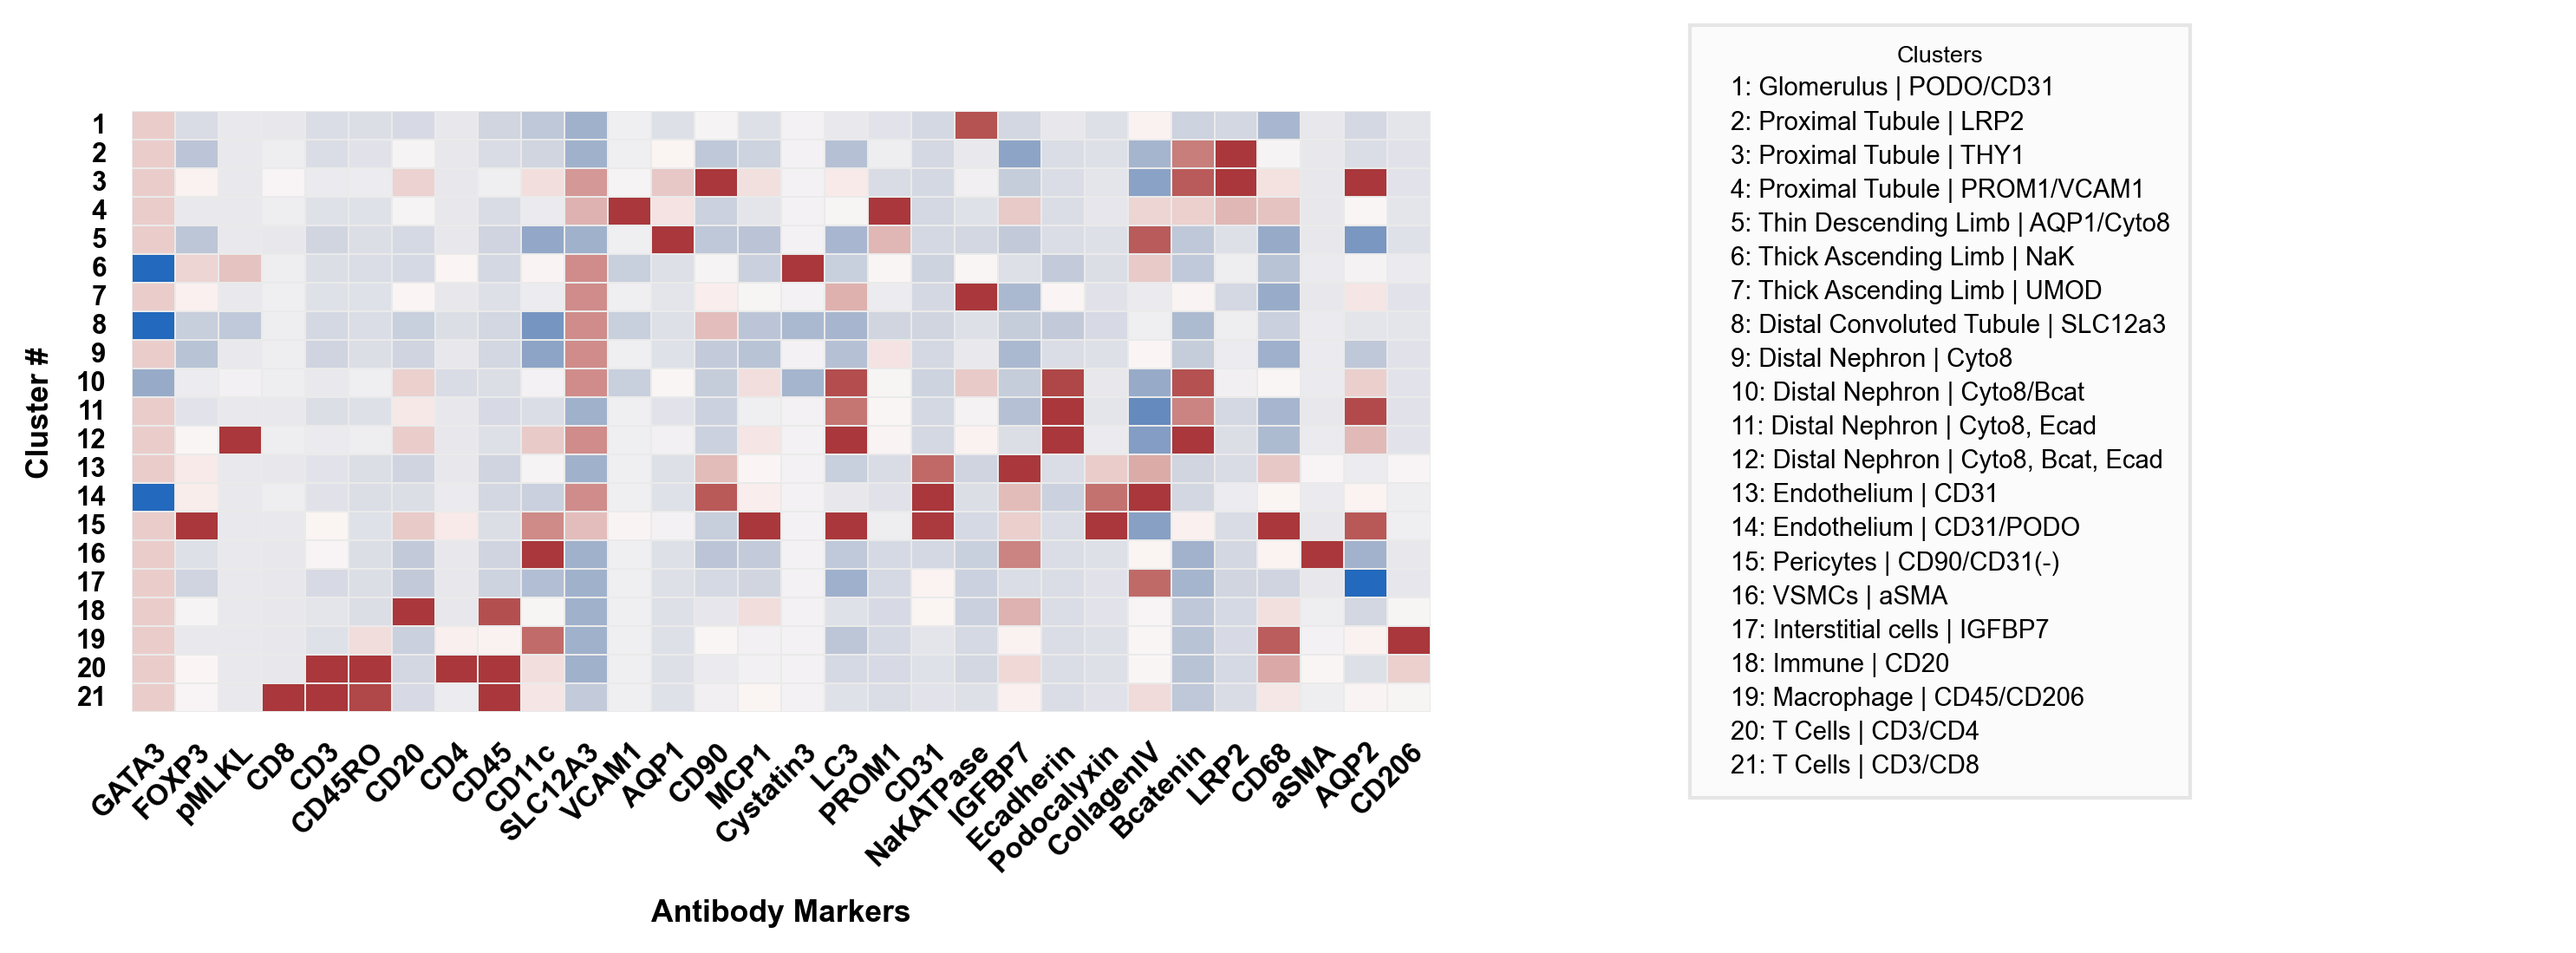

In [49]:
import os
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# =========================================================================
# 1. DEFINE CLUSTER GROUPS & EXACT ROW ORDER
# =========================================================================
# Define each row in your exact desired top-to-bottom order (1 to N).
# Multiple FastPG cluster numbers will be aggregated via median.
CLUSTER_CONFIG = [
    # --- Glomerular ---
    {"name": "Glomerulus | PODO/CD31", "fastpg": [1]},
    
    # --- Proximal Tubule ---
    {"name": "Proximal Tubule | LRP2", "fastpg": [15]},
    {"name": "Proximal Tubule | THY1", "fastpg": [16, 19]},
    {"name": "Proximal Tubule | PROM1/VCAM1", "fastpg": [9]},
    
    # --- Loop of Henle ---
    {"name": "Thin Descending Limb | AQP1/Cyto8", "fastpg": [18, 26]},
    {"name": "Thick Ascending Limb | NaK", "fastpg": [7]},  # Corrected from duplicate 1
    {"name": "Thick Ascending Limb | UMOD", "fastpg": [0, 23]},
    
    # --- Distal Nephron ---
    {"name": "Distal Convoluted Tubule | SLC12a3", "fastpg": [5]},
    {"name": "Distal Nephron | Cyto8", "fastpg": [2, 3, 24]},
    {"name": "Distal Nephron | Cyto8/Bcat", "fastpg": [12]},
    {"name": "Distal Nephron | Cyto8, Ecad", "fastpg": [17]},
    {"name": "Distal Nephron | Cyto8, Bcat, Ecad", "fastpg": [21]},
    
    # --- Endothelium ---
    {"name": "Endothelium | CD31", "fastpg": [10]},
    {"name": "Endothelium | CD31/PODO", "fastpg": [4]},
    
    # --- Interstitium / Stroma ---
    {"name": "Pericytes | CD90/CD31(-)", "fastpg": [20]},  # Corrected from duplicate 5
    {"name": "VSMCs | aSMA ", "fastpg": [14]},
    {"name": "Interstitial cells | IGFBP7", "fastpg": [6]},
    
    # --- Immune ---
    {"name": "Immune | CD20", "fastpg": [22]},
    {"name": "Macrophage | CD45/CD206", "fastpg": [8]},
    {"name": "T Cells | CD3/CD4", "fastpg": [11]},
    {"name": "T Cells | CD3/CD8", "fastpg": [13]},
]

# Build lookup mapping and extract exact row ordering
fastpg_to_name = {}
for item in CLUSTER_CONFIG:
    for f_id in item["fastpg"]:
        fastpg_to_name[f_id] = item["name"]

display_order = [item["name"] for item in CLUSTER_CONFIG]
row_numbers = [str(i) for i in range(1, len(display_order) + 1)]

# =========================================================================
# 2. LOAD DATA & COMPUTE MEDIANS
# =========================================================================
codex_path = r"C:\Users\jvill\OneDrive - UC San Diego\integrated_pipeline\WSI_data\CODEX\clusters-metadata\cluster_info.csv"
codex_df = pd.read_csv(codex_path)
if "Unnamed: 0" in codex_df.columns:
    codex_df = codex_df.drop(columns=["Unnamed: 0"])

ab_columns = codex_df.columns[4:-7]

# Filter down to selected FastPG IDs and assign display names
filtered_df = codex_df[codex_df["FastPG"].isin(fastpg_to_name.keys())].copy()
filtered_df["Display_Name"] = filtered_df["FastPG"].map(fastpg_to_name)

# Compute median expression across cells for each group
agg_df = filtered_df.groupby("Display_Name", observed=False)[ab_columns].median()
agg_df = agg_df.loc[display_order]  # Enforce top-to-bottom order

# Standardize to Z-scores across clusters
heatmap_data = agg_df.apply(lambda x: (x - x.mean()) / x.std(), axis=0)

# =========================================================================
# 3. PUBLICATION HEATMAP WITH NUMBERED ROWS & MATCHING LEGEND
# =========================================================================
plt.rcParams["font.sans-serif"] = ["Arial", "DejaVu Sans", "Helvetica"]
plt.rcParams["font.family"] = "sans-serif"

# 3-Panel Layout: [Heatmap (Numbered)] + [Colorbar] + [Legend Box]
fig = plt.figure(figsize=(12, 3), dpi=300)
gs = fig.add_gridspec(
    nrows=1,
    ncols=3,
    width_ratios=[0.58, 0.03, 0.39],
    wspace=0.12,
)

ax_heatmap = fig.add_subplot(gs[0])
# ax_cbar = fig.add_subplot(gs[1])
ax_legend = fig.add_subplot(gs[2])

# --- Heatmap Plot ---
sns.heatmap(
    heatmap_data,
    cmap="vlag",
    vmin=-2.0,
    vmax=2.0,
    center=0,
    linewidths=0.4,
    linecolor="#EAEAEA",
    cbar=True,
    cbar_ax=ax_cbar,
    ax=ax_heatmap,
    yticklabels=row_numbers,  # 1, 2, 3...
    xticklabels=True,
)

# Heatmap formatting
ax_heatmap.set_xticklabels(
    ax_heatmap.get_xticklabels(),
    rotation=45,
    ha="right",
    fontsize=8,
    rotation_mode="anchor",
    fontweight='bold'
)
ax_heatmap.set_yticklabels(
    row_numbers,
    rotation=0,
    fontsize=7.5,
    fontweight="bold",
)
ax_heatmap.set_xlabel("Antibody Markers", fontsize=8.5, fontweight="bold", labelpad=6)
ax_heatmap.set_ylabel("Cluster #", fontsize=8.5, fontweight="bold", labelpad=6)
ax_heatmap.tick_params(left=False, bottom=False)

# Colorbar formatting
ax_cbar.tick_params(labelsize=7)
ax_cbar.set_ylabel("Median Expression (Z-Score)", fontsize=7.5, fontweight="bold", labelpad=6)
# ax_cbar.set_label_position('left')

# --- Numbered Cluster Legend ---
legend_handles = []
for num, item in zip(row_numbers, CLUSTER_CONFIG):
    fastpg_str = ",".join(map(str, item["fastpg"]))
    label_text = f"{num}: {item['name']}"
    
    # Clean text-based legend handle
    patch = mpatches.Patch(
        facecolor="#4A7BB7",
        edgecolor="none",
        label=label_text,
    )
    legend_handles.append(patch)

ax_legend.axis("off")
ax_legend.legend(
    handles=legend_handles,
    title="Clusters",
    title_fontsize=6.5,
    fontsize=7.0,
    loc="center left",
    frameon=True,
    fancybox=False,
    edgecolor="#E0E0E0",
    facecolor="#FAFAFA",
    labelspacing=0.38,
    handlelength=0.0,
    handleheight=0.6,
    borderpad=0.8,
)

# ax.legend('off')

plt.savefig(
    r"C:\Users\jvill\OneDrive - UC San Diego\integrated_pipeline\WSI_data\CODEX\clusters-metadata\aggregated_numbered_heatmap-legend.png",
    bbox_inches="tight",
    dpi=300,
    transparent=True,
)
plt.show()


In [20]:
filtered_df

,Sample,Object,X,Y,GATA3,FOXP3,pMLKL,CD8,CD3,CD45RO,...,AQP2,CD206,HLA_DR,UMOD,Cytokeratin8,UMAP_1,UMAP_2,FastPG,FTUgroup,Display_Name
0,K21_198-3,0.0,1898.0,29522.5,-0.049408,-0.356540,-0.084746,-0.155853,-0.170844,-0.241988,...,-0.768159,-0.281907,0.099808,1.752035,-0.410567,-4.733756,0.267904,0,4.0,Thick Ascending Limb (UMOD)
1,K21_273-3,0.0,3415.0,1134.0,-0.056612,1.539778,-0.400777,-0.088231,-0.137154,-0.258837,...,-0.158559,-0.297387,-0.168262,-0.455982,-0.959539,-0.361139,-3.080480,5,7.0,Pericytes (CD90/CD31(-))
2,K21_198-3,1.0,4901.0,7410.5,-0.049408,-0.019572,-0.084746,-0.155853,-0.101519,-0.241988,...,0.207014,-0.239876,1.765037,-0.347571,1.507744,-0.423932,6.450483,17,6.0,"Distal Nephron (Cyto8, Ecad)"
3,K21_273-3,1.0,2746.0,10084.5,0.557261,0.406385,-0.490954,-0.073914,-0.574460,4.928891,...,0.062513,-0.267006,0.065864,-0.415135,-1.072046,-4.104335,-6.328611,8,NaN,Macrophage (CD45/CD206)
4,K21_198-3,10.0,1585.5,22516.5,0.023564,-0.192668,-0.084746,0.061982,-0.199087,-0.101231,...,0.739747,-0.277237,0.062803,-0.489019,-0.011176,5.800059,6.233115,15,2.0,Proximal Tubule (LRP2)
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
342716,K21_198-3,99997.0,2905.5,21642.5,-0.049408,-1.124252,-0.084746,0.037397,-0.330290,-0.178648,...,-0.581251,-0.291088,0.088706,-0.489416,1.632427,5.313918,5.411506,15,2.0,Proximal Tubule (LRP2)
342717,K21_273-3,99997.0,4157.5,12517.0,-0.073194,-0.378826,-0.079392,-0.088231,-0.623734,-0.258837,...,-0.092289,0.993629,1.039370,-0.242261,-1.018101,3.303141,-4.931132,4,7.0,Endothelium (CD31/PODO)
342718,K21_198-3,99998.0,2954.5,2903.0,-0.049408,-0.833601,-0.084746,-0.155853,-0.400226,-0.223359,...,-0.089362,-0.296417,0.253270,-0.288670,-0.413290,-1.501429,0.643525,1,4.0,Thick Ascending Limb (NaK)
342720,K21_198-3,99999.0,4042.0,26927.0,-0.049408,-0.173097,-0.084746,0.661960,-0.136181,0.201396,...,2.661199,-0.277926,0.477260,-0.421555,0.298083,8.828296,5.546354,16,2.0,Proximal Tubule (THY1)


In [ ]:
cluster_indeces